# Stochastic SIR Epidemic Conditioning

This notebook reproduces the SIR row of Figure 4 in *LatentFlow: A General Framework for Conditioning Stochastic Processes* (Sharrock, Astfalck & Moss, 2026). A **stochastic epidemic** is written as the deterministic image of Gaussian innovations, which drive the time-varying rates of an SIR model:

$$\frac{dS}{dt} = -\beta_t\,S\,I,\qquad \frac{dI}{dt} = \beta_t\,S\,I - \gamma_t\,I,\qquad \frac{dR}{dt} = \gamma_t\,I.$$

The transmission rate $\beta_t$ and recovery rate $\gamma_t$ are modulated by latent Brownian paths, and the initial infected fraction is itself a latent draw. Guidance then conditions the outbreak on

1. **data**: noisy observations of the infected fraction over the early window $t \le 3$;
2. **an event**: a fast epidemic that peaks high (peak $I > 0.32$) yet burns out (final $I < 0.18$) with a large final recovered fraction (final $R > 0.62$);
3. **both** at once.

Only the infected channel is ever constrained directly; the shared dynamics carry the information to $S$ and $R$.

## 1. Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import torch

from flow_inference.conditions import BinaryCondition, EqualityCondition, ProductCondition
from flow_inference.flows import GaussianIncrementFlow
from flow_inference.guidance import GuidanceMC
from flow_inference.maps import BaseMap
from flow_inference.sampler import IntegratorSampler

sys.path.insert(0, str(Path.cwd().parent))  # make examples/plotting.py importable
from matplotlib.lines import Line2D
from matplotlib.offsetbox import AnchoredOffsetbox, TextArea, VPacker
from plotting import as_numpy, plot_traces

torch.set_default_dtype(torch.float64)

## 2. Configuration

The time grid is defined at module level so the map and the conditions can both read it. The second cell holds the plotting and event-rate helpers reused by every figure.

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 0
torch.manual_seed(SEED)  # reproducible runs

num_samples = 72  # paths per prior / guided batch
num_times = 70  # time points per path
t_final = 12.0  # time horizon
dt = t_final / (num_times - 1)
times = torch.linspace(0.0, t_final, num_times, device=device)
NUM_STEPS = 100  # flow integration steps

OBS_WINDOW = 3.0  # observations are taken on t <= OBS_WINDOW
OBS_NOISE = 0.01  # observation noise standard deviation (population fraction)
PEAK_I, FINAL_I, FINAL_R = 0.32, 0.18, 0.62  # the fast-epidemic thresholds

CHANNELS = ["S", "I", "R"]
COLORS = {"S": "#2563eb", "I": "#dc2626", "R": "#16a34a"}
EVENT_LINES = [  # components of the event, for the threshold lines and the event box
    {"text": f"peak I > {PEAK_I}", "color": COLORS["I"], "channel": "I", "y": PEAK_I, "span": "path"},
    {"text": f"final I < {FINAL_I}", "color": COLORS["I"], "channel": "I", "y": FINAL_I, "span": "final"},
    {"text": f"final R > {FINAL_R}", "color": COLORS["R"], "channel": "R", "y": FINAL_R, "span": "final"},
]

In [3]:
def plot_paths(ax, samples, title, ylabel="population fraction"):
    """Every sample path of every channel of (B, C, num_times) samples."""
    for channel, name in enumerate(CHANNELS):
        plot_traces(samples, x=times, channel=channel, color=COLORS[name], count=samples.shape[0],
                    alpha=0.4, linewidth=1.2, ax=ax)
    ax.set_title(title, pad=8)
    ax.set_xlabel("time")
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    ax.set_ylim(*(0.0, 1.0))
    ax.grid(True, color="#e5e7eb", linewidth=0.8)
    ax.margins(x=0.01)


def channel_legend(ax, loc):
    handles = [Line2D([], [], color=COLORS[name], linewidth=2.0, label=name) for name in CHANNELS]
    ax.legend(handles=handles, loc=loc)


def show_event(ax, loc):
    threshold_lines({name: ax for name in CHANNELS})
    event_box(ax, loc)


def plot_observations(ax, observations, channels, mask, transform=lambda y: y):
    """Observed values as black dots."""
    for channel in channels:
        ax.scatter(as_numpy(times[mask]), as_numpy(transform(observations[channel, mask])),
                   color="black", edgecolor="white", linewidth=0.6, s=30, zorder=5)


def event_box(ax, loc):
    """The event's components as coloured lines of text in a white box, as in the paper."""
    lines = [TextArea(line["text"], textprops=dict(color=line["color"], fontsize=9)) for line in EVENT_LINES]
    box = AnchoredOffsetbox(loc=loc, child=VPacker(children=lines, align="left", pad=0, sep=2),
                            pad=0.4, borderpad=0.6, frameon=True)
    box.patch.set_boxstyle("round")
    box.patch.set_edgecolor("#9ca3af")
    ax.add_artist(box)


def threshold_lines(axes_by_channel):
    """A dashed line at every event threshold: across the whole path for extremes, over the
    final stretch for terminal conditions."""
    for line in EVENT_LINES:
        xmin = 0.0 if line["span"] == "path" else 0.85
        axes_by_channel[line["channel"]].axhline(line["y"], xmin=xmin, color=line["color"],
                                                 linestyle="--", linewidth=1.5, zorder=4)


def smooth_max(values: torch.Tensor, tau: float) -> torch.Tensor:
    """Log-sum-exp maximum over time: differentiable, and within tau * log(num_times) of the hard max."""
    return tau * torch.logsumexp(values / tau, dim=-1)


def smooth_min(values: torch.Tensor, tau: float) -> torch.Tensor:
    return -smooth_max(-values, tau)


def event_rate(condition: BinaryCondition, samples: torch.Tensor) -> float:
    """Fraction of samples meeting every component of the event (all margins > 0)."""
    margins = condition.smooth_eval_condition(samples).squeeze(1)  # (B, components)
    return (margins.min(dim=-1).values > 0).double().mean().item()

## 3. The Stochastic SIR Simulator

`SIRMap` is the generator $T_\vartheta$: it integrates the compartments with an explicit Euler step. The first two latent channels are accumulated into Brownian paths that modulate $\beta_t$ and $\gamma_t$, and the first entry of the third sets the initial infected fraction; because $(S, I, R)$ share these dynamics, the map consumes the whole `(B, 3, num_times)` latent tensor.

In [4]:
class SIRMap(BaseMap):
    """Coupled (S, I, R) Euler simulator with latent-driven transmission and recovery rates."""

    def __init__(self, num_times: int, dt: float):
        super().__init__(
            latent_dim=num_times,
            output_shape=(num_times,),
            channels=3,
            device=device,
            dtype=torch.float64,
        )
        self.num_times = num_times
        self.dt = dt

    def _map(self, z: torch.Tensor) -> torch.Tensor:
        """z: (B, 3, num_times) iid N(0, 1) -> (B, 3, num_times) (S, I, R) paths."""
        B, C, N = z.shape
        if C != 3 or N != self.num_times:
            raise ValueError(f"expected latent shape (B, 3, {self.num_times}), got {tuple(z.shape)}")

        sqrt_dt = self.dt ** 0.5
        beta_noise = torch.cumsum(z[:, 0, :] * sqrt_dt, dim=-1)
        gamma_noise = torch.cumsum(z[:, 1, :] * sqrt_dt, dim=-1)
        beta_t = 0.70 * torch.exp(0.32 * torch.tanh(0.35 * beta_noise))
        gamma_t = 0.25 * torch.exp(0.24 * torch.tanh(0.35 * gamma_noise))

        infected = 0.012 + 0.045 * torch.sigmoid(z[:, 2, 0])
        recovered = torch.zeros_like(infected)
        susceptible = 1.0 - infected - recovered

        s_path = [susceptible]
        i_path = [infected]
        r_path = [recovered]

        for k in range(self.num_times - 1):
            infection = beta_t[:, k] * susceptible * infected
            recovery = gamma_t[:, k] * infected
            susceptible = susceptible - infection * self.dt
            infected = infected + (infection - recovery) * self.dt
            recovered = recovered + recovery * self.dt
            s_path.append(susceptible)
            i_path.append(infected)
            r_path.append(recovered)

        return torch.stack(
            [torch.stack(s_path, dim=-1), torch.stack(i_path, dim=-1), torch.stack(r_path, dim=-1)],
            dim=1,
        )  # (B, 3, num_times)

## 4. Prior

`GaussianIncrementFlow` runs the flow over the iid Gaussian increments and pushes them through the map, so sampling it without guidance gives unconditioned prior outbreaks.

  0%|          | 0/99 [00:00<?, ?it/s]

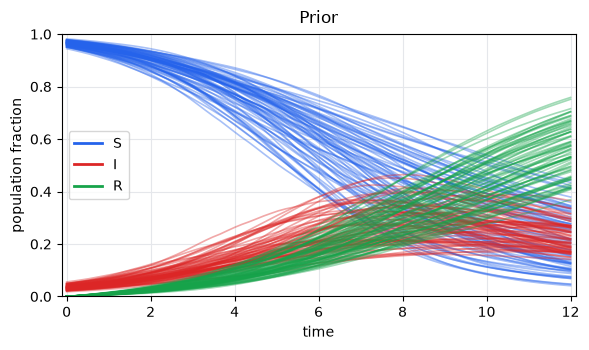

In [5]:
flow = GaussianIncrementFlow(map=SIRMap(num_times, dt), device=device)
sampler = IntegratorSampler(flow=flow)
prior_samples = sampler.sample(num_samples, num_steps=NUM_STEPS).detach()

fig, ax = plt.subplots(figsize=(6, 3.6))
plot_paths(ax, prior_samples, "Prior")
channel_legend(ax, loc="center left")
plt.tight_layout()

## 5. Conditioned on Data

Take one prior outbreak as the "truth" and observe only its infected fraction at every other time point of the early window $t \le 3$, with Gaussian noise of standard deviation $0.01$. `NoisyObservation` is an `EqualityCondition` whose `sigma` is that noise level. The early growth of $I$ fixes the transmission rate, which in turn constrains $S$ and $R$.

  0%|          | 0/99 [00:00<?, ?it/s]

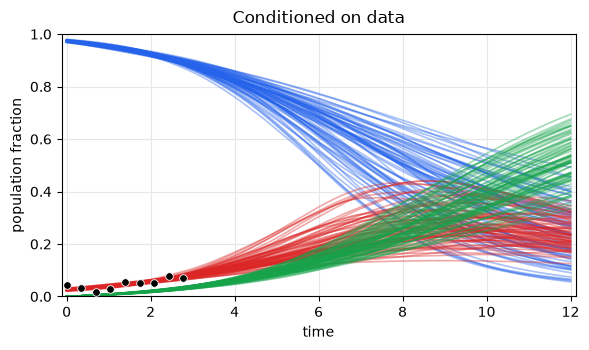

In [6]:
truth = prior_samples[2]
obs_mask = (times <= OBS_WINDOW) & (torch.arange(num_times, device=device) % 2 == 0)
obs_channels = torch.tensor([1], device=device)  # infected only
generator = torch.Generator(device=device).manual_seed(SEED)
observations = truth + OBS_NOISE * torch.randn(truth.shape, device=device, generator=generator)


class NoisyObservation(EqualityCondition):
    """Gaussian observations of `channels` at the masked times, with noise standard deviation `sigma`."""

    def __init__(self, observations: torch.Tensor, channels: torch.Tensor, mask: torch.Tensor, sigma: float):
        super().__init__(sigma=sigma)
        self.register_buffer("observations", observations)
        self.register_buffer("channels", channels)
        self.register_buffer("mask", mask)

    def residual(self, x: torch.Tensor) -> torch.Tensor:
        selected = x[:, self.channels][:, :, self.mask]
        target = self.observations[self.channels][:, self.mask]
        return selected - target[None, :, :]


data_condition = NoisyObservation(observations, obs_channels, obs_mask, sigma=OBS_NOISE)
data_guidance = GuidanceMC(flow, data_condition).to(device)
data_samples = sampler.sample(num_samples, guidance=data_guidance, num_steps=NUM_STEPS).detach()

fig, ax = plt.subplots(figsize=(6, 3.6))
plot_paths(ax, data_samples, "Conditioned on data")
plot_observations(ax, observations, [1], obs_mask)
plt.tight_layout()

## 6. Conditioned on an Event

Now condition on the fast-epidemic event alone. `FastEpidemic` is a `BinaryCondition` that stacks one margin per component (positive when satisfied), using a smooth log-sum-exp maximum for the peak; guidance must satisfy all three at once. Only a few percent of prior outbreaks do.

  0%|          | 0/99 [00:00<?, ?it/s]

P(fast epidemic): prior=0.064  guided=1.000


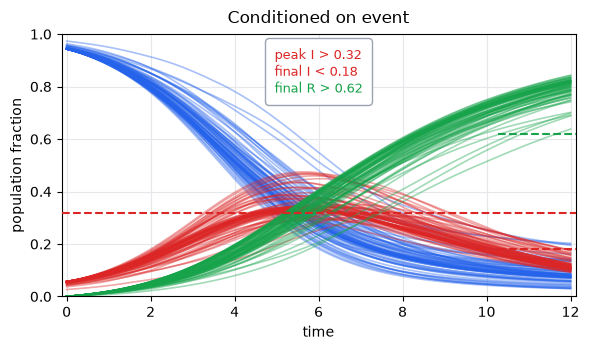

In [7]:
class FastEpidemic(BinaryCondition):
    """Peak I above `peak_i`, final I below `final_i` and final R above `final_r`."""

    def __init__(self, peak_i: float, final_i: float, final_r: float, v: float = 1e-5, smooth_tau: float = 0.015):
        super().__init__(v=v)
        self.peak_i, self.final_i, self.final_r = peak_i, final_i, final_r
        self.smooth_tau = smooth_tau

    def smooth_eval_condition(self, x: torch.Tensor) -> torch.Tensor:
        infected = x[:, 1, :]
        recovered = x[:, 2, :]
        components = torch.stack(
            [
                smooth_max(infected, self.smooth_tau) - self.peak_i,
                self.final_i - infected[:, -1],
                recovered[:, -1] - self.final_r,
            ],
            dim=-1,
        )
        return components[:, None, :]  # (B, 1, 3)


event_condition = FastEpidemic(PEAK_I, FINAL_I, FINAL_R)
event_guidance = GuidanceMC(flow, event_condition).to(device)
event_samples = sampler.sample(num_samples, guidance=event_guidance, num_steps=NUM_STEPS).detach()

event_prior_samples = flow.map(torch.randn(20_000, 3, num_times, device=device))  # large prior batch for the rate
print(f"P(fast epidemic): prior={event_rate(event_condition, event_prior_samples):.3f}  "
      f"guided={event_rate(event_condition, event_samples):.3f}")

fig, ax = plt.subplots(figsize=(6, 3.6))
plot_paths(ax, event_samples, "Conditioned on event")
show_event(ax, loc="upper center")
plt.tight_layout()

## 7. Conditioned on Both

`ProductCondition` multiplies the two likelihoods, so guidance must follow the observed early growth **and** produce the fast epidemic.

In [8]:
both_guidance = GuidanceMC(flow, ProductCondition([data_condition, event_condition])).to(device)
both_samples = sampler.sample(num_samples, guidance=both_guidance, num_steps=NUM_STEPS).detach()

print(f"P(fast epidemic) given both: {event_rate(event_condition, both_samples):.3f}")
obs_error = (both_samples[:, 1, obs_mask] - truth[None, 1, obs_mask]).abs().mean().item()
print(f"mean |error| at the observed points: {obs_error:.4f} (observation noise sd {OBS_NOISE})")

  0%|          | 0/99 [00:00<?, ?it/s]

P(fast epidemic) given both: 1.000
mean |error| at the observed points: 0.0068 (observation noise sd 0.01)


## 8. Summary

The four regimes side by side, as in Figure 4 of the LatentFlow paper. The same prior, flow and sampler are used throughout; only the condition changes.

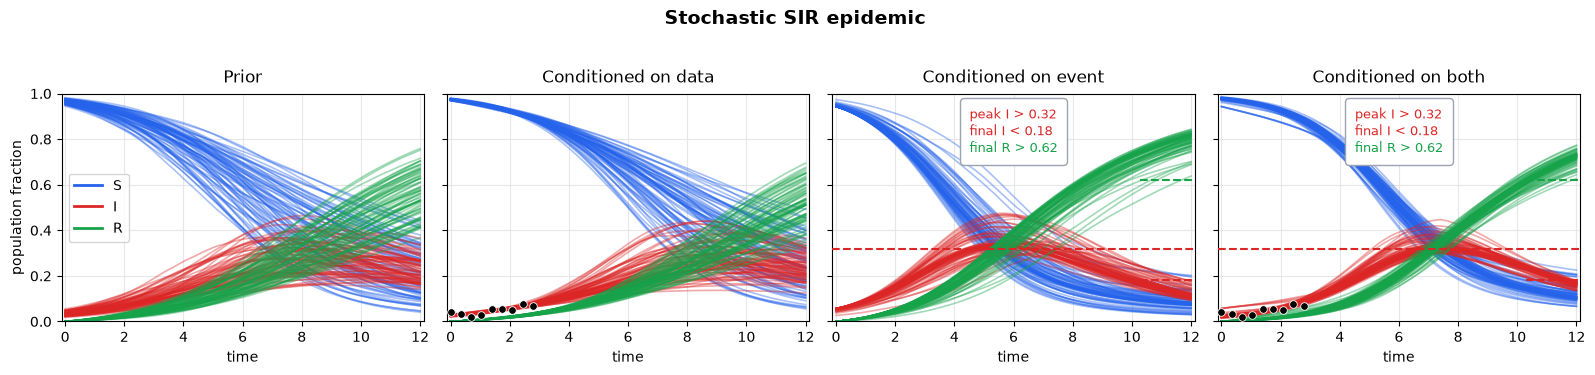

In [9]:
panels = [
    (prior_samples, "Prior"),
    (data_samples, "Conditioned on data"),
    (event_samples, "Conditioned on event"),
    (both_samples, "Conditioned on both"),
]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharex=True, sharey=True)
for i, (ax, (samples, panel_title)) in enumerate(zip(axes, panels)):
    plot_paths(ax, samples, panel_title)
    if i:
        ax.set_ylabel(None)
    if i in (1, 3):
        plot_observations(ax, observations, [1], obs_mask)
    if i in (2, 3):
        show_event(ax, loc="upper center")
channel_legend(axes[0], loc="center left")
fig.suptitle("Stochastic SIR epidemic", y=1.03, fontsize=14, fontweight="bold")
plt.tight_layout()